# Portfolio 3: Advanced ML and Deep Learning
**Pham Quang Minh | Student ID: 104999568**

COS40007 Artificial Intelligence Engineering

GitHub: https://github.com/theh9j/COS40007

Started: 1 November 2026

**Checkpoint 3: Random Forest and MLP compared.**
Keras ANN experiments will be added in later iterations.

## Problem and data
Continue the Concrete Compressive Strength project using **option 3d: a tabular ANN**.
The working target is the four strength groups from Portfolio 2.

The checked data has 1,005 records and eight original inputs. The existing recipe
split has 676 training records and 329 test records. Each training class has 169
records. No missing values or shared train/test recipes were found.

The data is in `data/concrete_partitioned.csv`. The verification record is in
`checks/iteration-01-data-audit.json`. Keep target strength, class labels and ID
columns out of the model inputs.

## Part A.1 - Prepare the inputs
Keep the eight original ingredient/age measurements and the four existing strength
classes. Use the saved recipe split from Portfolio 2: 676 training rows and 329 test
rows. No target, ID or partition columns are used as inputs.

Class boundaries are kept as the fixed task definition from Portfolio 2; they are
not recalculated on test data. Earlier portfolios inspected this dataset, so these
results still need external validation.

In [1]:
from pathlib import Path
import json
import hashlib
import pickle
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

SEED = 42
FEATURES = ['cement', 'slag', 'fly_ash', 'water', 'superplasticizer',
            'coarse_aggregate', 'fine_aggregate', 'age']
CLASS_NAMES = ['Lower', 'Lower-middle', 'Upper-middle', 'Higher']
DATA_PATH = Path('data/concrete_partitioned.csv')
audit_01 = json.loads(Path('checks/iteration-01-data-audit.json').read_text())
source_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
assert source_hash == audit_01['copied_sha256'], 'The checked dataset has changed.'
data = pd.read_csv(DATA_PATH)
assert data.source_row.is_unique and data.notna().all().all()
train = data.loc[data.partition.eq('train')].copy()
test = data.loc[data.partition.eq('test')].copy()
X_train, X_test = train[FEATURES], test[FEATURES]
y_train = train.strength_class_code.astype(int)
y_test = test.strength_class_code.astype(int)
groups = train.recipe_group.to_numpy()
assert X_train.shape == (676, 8) and X_test.shape == (329, 8)
assert set(groups).isdisjoint(test.recipe_group)
assert np.isfinite(data[FEATURES].to_numpy()).all()
for folder in ['results', 'figures', 'models', 'checks']:
    Path(folder).mkdir(exist_ok=True)
print('Training shape:', X_train.shape, '| Target shape:', y_train.shape)
print('Test shape:', X_test.shape, '| Target shape:', y_test.shape)
print('Inputs:', ', '.join(FEATURES))
print('Shared training/test recipes: 0')

Training shape: (676, 8) | Target shape: (676,)
Test shape: (329, 8) | Target shape: (329,)
Inputs: cement, slag, fly_ash, water, superplasticizer, coarse_aggregate, fine_aggregate, age
Shared training/test recipes: 0


## Part A.2 - Random Forest and five-fold checks
A Random Forest combines predictions from many decision trees. Start with 200
trees and at least two training records per leaf. These settings are fixed for
this baseline; no search uses the test results.

StandardScaler is inside the pipeline, so it learns from training rows only.
Trees usually do not need scaling, but this sets up a consistent workflow for the
MLP next. Each CV fold also learns its own scaler.

Five-fold CV checks different groups of training recipes. Accuracy is the fraction
predicted correctly. Weighted F1 combines precision and recall, weighting classes
by their number of records. Higher scores are better.

In [2]:
baseline = Pipeline([
    ('scale', StandardScaler()),
    ('model', RandomForestClassifier(n_estimators=200, min_samples_leaf=2,
                                      random_state=SEED, n_jobs=1))
])
cv = GroupKFold(n_splits=5, shuffle=True, random_state=SEED)
folds = list(cv.split(X_train, y_train, groups))
for fit_idx, valid_idx in folds:
    assert set(groups[fit_idx]).isdisjoint(groups[valid_idx])

cv_scores = cross_validate(baseline, X_train, y_train, cv=folds,
    scoring={'accuracy': 'accuracy', 'f1_weighted': 'f1_weighted'},
    return_estimator=True, n_jobs=1, error_score='raise')

# Verify every scaler used only its fold's fitting rows.
fold_rows, assignment_rows = [], []
for fold, ((fit_idx, valid_idx), fitted) in enumerate(
        zip(folds, cv_scores['estimator']), start=1):
    np.testing.assert_allclose(fitted.named_steps['scale'].mean_,
                               X_train.iloc[fit_idx].mean().to_numpy())
    fold_rows.append({'fold': fold,
        'accuracy': float(cv_scores['test_accuracy'][fold - 1]),
        'f1_weighted': float(cv_scores['test_f1_weighted'][fold - 1]),
        'fit_rows': len(fit_idx), 'validation_rows': len(valid_idx),
        'shared_recipes': 0})
    for source_id in train.iloc[valid_idx].source_row:
        assignment_rows.append({'source_row': int(source_id), 'validation_fold': fold})
fold_results = pd.DataFrame(fold_rows)
fold_results.to_csv('results/random_forest_cv.csv', index=False)
pd.DataFrame(assignment_rows).sort_values('source_row').to_csv(
    'checks/cv_recipe_folds.csv', index=False)
print(fold_results[['fold', 'accuracy', 'f1_weighted']].round(4).to_string(index=False))
print(f'Mean CV accuracy: {fold_results.accuracy.mean():.2%}')
print(f'Mean CV weighted F1: {fold_results.f1_weighted.mean():.4f}')

 fold  accuracy  f1_weighted
    1    0.6328       0.6389
    2    0.7200       0.7208
    3    0.7462       0.7454
    4    0.6471       0.6446
    5    0.7121       0.7128
Mean CV accuracy: 69.16%
Mean CV weighted F1: 0.6925


## Part A.3 - Check the separate test set
Fit the fixed baseline on all training recipes, then evaluate it on the saved test
recipes. Keep these results as the reference for the MLP. Do not change settings
just to improve this test score.

In [3]:
baseline.fit(X_train, y_train)
np.testing.assert_allclose(baseline.named_steps['scale'].mean_,
                           X_train.mean().to_numpy())
train_prediction = baseline.predict(X_train)
test_prediction = baseline.predict(X_test)
assert set(test_prediction).issubset(range(4))
metrics = {
    'model': 'Random Forest',
    'train_accuracy': float(accuracy_score(y_train, train_prediction)),
    'cv_accuracy_mean': float(fold_results.accuracy.mean()),
    'cv_accuracy_sd': float(fold_results.accuracy.std(ddof=1)),
    'cv_f1_weighted_mean': float(fold_results.f1_weighted.mean()),
    'cv_f1_weighted_sd': float(fold_results.f1_weighted.std(ddof=1)),
    'test_accuracy': float(accuracy_score(y_test, test_prediction)),
    'test_f1_weighted': float(f1_score(y_test, test_prediction,
                                      average='weighted', zero_division=0))
}
print(f'Test accuracy: {metrics["test_accuracy"]:.2%}')
print(f'Test weighted F1: {metrics["test_f1_weighted"]:.4f}')
print(f'Training accuracy: {metrics["train_accuracy"]:.2%}')
print(classification_report(y_test, test_prediction, labels=range(4),
    target_names=CLASS_NAMES, digits=3, zero_division=0))
pd.DataFrame([metrics]).to_csv('results/model_comparison.csv', index=False)
pd.DataFrame({'source_row': test.source_row.to_numpy(),
              'actual_class': y_test.to_numpy(),
              'predicted_class': test_prediction}).to_csv(
    'results/random_forest_test_predictions.csv', index=False)

Test accuracy: 78.12%
Test weighted F1: 0.7805
Training accuracy: 97.19%
              precision    recall  f1-score   support

       Lower      0.895     0.883     0.889        77
Lower-middle      0.649     0.667     0.658        72
Upper-middle      0.716     0.674     0.695        86
      Higher      0.847     0.883     0.865        94

    accuracy                          0.781       329
   macro avg      0.777     0.777     0.776       329
weighted avg      0.781     0.781     0.781       329



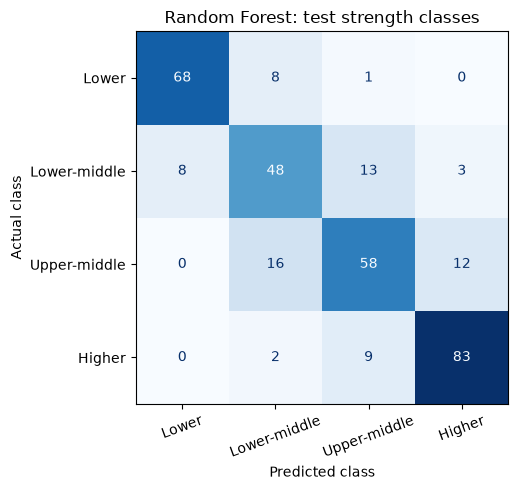

In [4]:
fig, ax = plt.subplots(figsize=(6.5, 5))
ConfusionMatrixDisplay.from_predictions(y_test, test_prediction,
    labels=range(4), display_labels=CLASS_NAMES, cmap='Blues',
    values_format='d', colorbar=False, ax=ax, xticks_rotation=20)
ax.set_title('Random Forest: test strength classes')
ax.set_xlabel('Predicted class')
ax.set_ylabel('Actual class')
fig.tight_layout()
fig.savefig('figures/random_forest_confusion_matrix.png', dpi=180)
plt.show()
plt.close(fig)

## Part A.4 - Save and verify the baseline
Save the whole pipeline, including its fitted scaler. Check that loading our own
saved file produces exactly the same predictions. The fold assignments are also
saved so the next model can use the same five-fold comparison.

In [5]:
model_path = Path('models/random_forest_baseline.pkl')
with model_path.open('wb') as stream:
    pickle.dump(baseline, stream, protocol=pickle.HIGHEST_PROTOCOL)
# Load only the model file created by this notebook.
with model_path.open('rb') as stream:
    restored = pickle.load(stream)
np.testing.assert_array_equal(restored.predict(X_test), test_prediction)
assignment = pd.read_csv('checks/cv_recipe_folds.csv')
assert assignment.source_row.is_unique and len(assignment) == len(train)
metadata = {
    'student_id': '104999568', 'name': 'Pham Quang Minh',
    'github': 'https://github.com/theh9j/COS40007',
    'iteration': 2, 'date': '2026-11-01', 'seed': SEED,
    'features': FEATURES, 'class_names': CLASS_NAMES,
    'class_cutoffs_MPa': audit_01['class_cutoffs_MPa'],
    'label_policy': 'Fixed class definition inherited from Portfolio 2',
    'source_sha256': source_hash,
    'train_shape': list(X_train.shape), 'test_shape': list(X_test.shape),
    'cv': '5-fold GroupKFold by recipe; seed 42; training partition only',
    'cv_scalers_fit_on_fold_training_only': True,
    'final_scaler_fit_on_training_only': True,
    'shared_train_test_recipes': 0, 'shared_cv_recipes': 0,
    'saved_model_predictions_match': True,
    'model_parameters': baseline.named_steps['model'].get_params(),
    'metrics': metrics,
    'versions': {'python': platform.python_version(), 'sklearn': sklearn.__version__,
                 'numpy': np.__version__, 'pandas': pd.__version__},
    'ai_assistance': 'Baseline code drafting, explanations and verification'
}
Path('checks/iteration-02-checks.json').write_text(json.dumps(metadata, indent=2))
print('Saved model, CV scores, fold assignments, test predictions and checks.')
print('Training-only scaling and saved-model checks passed.')

Saved model, CV scores, fold assignments, test predictions and checks.
Training-only scaling and saved-model checks passed.


## Random Forest baseline results
The Random Forest correctly classified **78.1%** of test records, with weighted F1 **0.781**. Across five recipe-group folds, mean accuracy was **69.2%** and mean weighted F1 was **0.693**. Training accuracy was **97.2%**; the difference from CV performance suggests that training results are optimistic.

These results provide the reference for the MLP comparison below.

## Part A.5 - Add an MLP classifier
An MLP is a neural network for tabular data. Start with the supplied teaching
example's two hidden layers (100 and 50 units), ReLU, Adam and up to 500 iterations.
The settings are fixed before checking test performance.

Use the same eight inputs, labels, recipe split and five saved CV folds as the
Random Forest. StandardScaler stays inside the pipeline. Internal random validation
is disabled so it cannot split related recipes. Any convergence warnings are
recorded rather than hidden.

Reference: the supplied `MLP_Classifcation.ipynb`, adapted from Iris to concrete data.

In [6]:
import warnings
from sklearn.neural_network import MLPClassifier
from sklearn.exceptions import ConvergenceWarning

# Reconstruct the exact saved folds instead of drawing another random split.
saved_folds = pd.read_csv('checks/cv_recipe_folds.csv')
assert saved_folds.source_row.is_unique
fold_id = train.source_row.map(
    saved_folds.set_index('source_row').validation_fold).to_numpy()
assert not pd.isna(fold_id).any()
mlp_folds = [(np.flatnonzero(fold_id != k), np.flatnonzero(fold_id == k))
             for k in range(1, 6)]
for (a, b), (old_a, old_b) in zip(mlp_folds, folds):
    np.testing.assert_array_equal(a, old_a)
    np.testing.assert_array_equal(b, old_b)
    assert set(groups[a]).isdisjoint(groups[b])

mlp = Pipeline([
    ('scale', StandardScaler()),
    ('model', MLPClassifier(hidden_layer_sizes=(100, 50), activation='relu',
        solver='adam', max_iter=500, early_stopping=False, random_state=SEED))
])
with warnings.catch_warnings(record=True) as cv_warnings:
    warnings.simplefilter('always', ConvergenceWarning)
    mlp_cv = cross_validate(mlp, X_train, y_train, cv=mlp_folds,
        scoring={'accuracy':'accuracy', 'f1_weighted':'f1_weighted'},
        return_estimator=True, n_jobs=1, error_score='raise')
cv_convergence = [str(w.message) for w in cv_warnings
                  if issubclass(w.category, ConvergenceWarning)]
mlp_fold_rows = []
for k, ((a, b), fitted) in enumerate(zip(mlp_folds, mlp_cv['estimator']), 1):
    np.testing.assert_allclose(fitted.named_steps['scale'].mean_,
                               X_train.iloc[a].mean().to_numpy())
    mlp_fold_rows.append({'fold':k,
        'accuracy':float(mlp_cv['test_accuracy'][k-1]),
        'f1_weighted':float(mlp_cv['test_f1_weighted'][k-1]),
        'iterations':int(fitted.named_steps['model'].n_iter_),
        'final_training_loss':float(fitted.named_steps['model'].loss_),
        'fit_rows':len(a), 'validation_rows':len(b), 'shared_recipes':0})
mlp_fold_results = pd.DataFrame(mlp_fold_rows)
mlp_fold_results.to_csv('results/mlp_cv.csv',index=False)
print(mlp_fold_results[['fold','accuracy','f1_weighted','iterations']]
      .round(4).to_string(index=False))
print('CV convergence warnings:', len(cv_convergence))

 fold  accuracy  f1_weighted  iterations
    1    0.6719       0.6711         500
    2    0.7933       0.7907         500
    3    0.8308       0.8318         500
    4    0.7132       0.7130         500
    5    0.7500       0.7472         500
CV convergence warnings: 5


In [7]:
with warnings.catch_warnings(record=True) as fit_warnings:
    warnings.simplefilter('always', ConvergenceWarning)
    mlp.fit(X_train, y_train)
fit_convergence = [str(w.message) for w in fit_warnings
                   if issubclass(w.category, ConvergenceWarning)]
np.testing.assert_allclose(mlp.named_steps['scale'].mean_,
                           X_train.mean().to_numpy())
mlp_prediction = mlp.predict(X_test)
mlp_metrics = {
    'model':'MLP',
    'train_accuracy':float(accuracy_score(y_train, mlp.predict(X_train))),
    'cv_accuracy_mean':float(mlp_fold_results.accuracy.mean()),
    'cv_accuracy_sd':float(mlp_fold_results.accuracy.std(ddof=1)),
    'cv_f1_weighted_mean':float(mlp_fold_results.f1_weighted.mean()),
    'cv_f1_weighted_sd':float(mlp_fold_results.f1_weighted.std(ddof=1)),
    'test_accuracy':float(accuracy_score(y_test, mlp_prediction)),
    'test_f1_weighted':float(f1_score(y_test, mlp_prediction,
                                     average='weighted', zero_division=0))}
comparison = pd.DataFrame([metrics, mlp_metrics])
comparison.to_csv('results/model_comparison.csv',index=False)
print(comparison[['model','cv_accuracy_mean','cv_f1_weighted_mean',
                  'test_accuracy','test_f1_weighted']].round(4).to_string(index=False))
print('Final MLP iterations:', mlp.named_steps['model'].n_iter_)
print('Final-fit convergence warnings:', len(fit_convergence))
print(classification_report(y_test, mlp_prediction, labels=range(4),
    target_names=CLASS_NAMES, digits=3, zero_division=0))

        model  cv_accuracy_mean  cv_f1_weighted_mean  test_accuracy  test_f1_weighted
Random Forest            0.6916               0.6925         0.7812            0.7805
          MLP            0.7518               0.7507         0.8207            0.8203
Final MLP iterations: 500
Final-fit convergence warnings: 1
              precision    recall  f1-score   support

       Lower      0.873     0.896     0.885        77
Lower-middle      0.773     0.708     0.739        72
Upper-middle      0.750     0.802     0.775        86
      Higher      0.880     0.862     0.871        94

    accuracy                          0.821       329
   macro avg      0.819     0.817     0.817       329
weighted avg      0.821     0.821     0.820       329



## Part A.6 - Compare the models
The chart shows mean CV accuracy and separate test accuracy. Error bars show the
variation across the five CV folds, not a confidence interval. Select the traditional
baseline by CV accuracy before comparing it with the later ANN.

The second chart shows which strength classes the MLP confuses. These results do
not trigger further tuning on the test set.

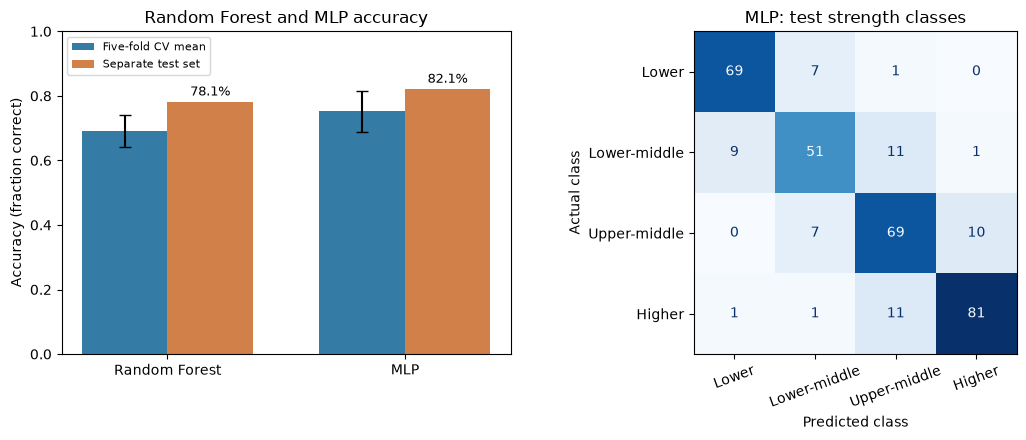

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
positions = np.arange(len(comparison))
axes[0].bar(positions-.18, comparison.cv_accuracy_mean, width=.36,
             label='Five-fold CV mean', color='#347ca5')
axes[0].bar(positions+.18, comparison.test_accuracy, width=.36,
             label='Separate test set', color='#d08048')
axes[0].errorbar(positions-.18, comparison.cv_accuracy_mean,
    yerr=comparison.cv_accuracy_sd, fmt='none', color='black', capsize=4)
axes[0].set(xticks=positions, xticklabels=comparison.model,
             ylim=(0, 1), ylabel='Accuracy (fraction correct)',
             title='Random Forest and MLP accuracy')
axes[0].legend(fontsize=8)
for i, value in enumerate(comparison.test_accuracy):
    axes[0].text(i+.18,value+.02,f'{value:.1%}',ha='center',fontsize=9)
ConfusionMatrixDisplay.from_predictions(y_test, mlp_prediction,
    labels=range(4), display_labels=CLASS_NAMES, cmap='Blues', values_format='d',
    colorbar=False, ax=axes[1], xticks_rotation=20)
axes[1].set(title='MLP: test strength classes',
             xlabel='Predicted class', ylabel='Actual class')
fig.tight_layout()
fig.savefig('figures/traditional_models_comparison.png', dpi=180)
plt.show()
plt.close(fig)

In [9]:
mlp_path = Path('models/mlp_baseline.pkl')
with mlp_path.open('wb') as stream:
    pickle.dump(mlp, stream, protocol=pickle.HIGHEST_PROTOCOL)
with mlp_path.open('rb') as stream:
    restored_mlp = pickle.load(stream)
np.testing.assert_array_equal(restored_mlp.predict(X_test),mlp_prediction)
pd.DataFrame({'source_row':test.source_row.to_numpy(),
              'actual_class':y_test.to_numpy(),
              'predicted_class':mlp_prediction}).to_csv(
    'results/mlp_test_predictions.csv',index=False)
pd.DataFrame({'iteration':np.arange(1,mlp.named_steps['model'].n_iter_+1),
              'training_loss':mlp.named_steps['model'].loss_curve_}).to_csv(
    'results/mlp_training_loss.csv',index=False)
best_traditional = comparison.loc[comparison.cv_accuracy_mean.idxmax(),'model']
checks_03 = {
    'iteration':3, 'date':'2026-11-01', 'student_id':'104999568',
    'name':'Pham Quang Minh', 'seed':SEED, 'source_sha256':source_hash,
    'features':FEATURES, 'class_names':CLASS_NAMES,
    'same_split_and_cv_folds_as_random_forest':True,
    'cv_scalers_fit_on_fold_training_only':True,
    'final_scaler_fit_on_training_only':True,
    'saved_model_predictions_match':True,
    'model_parameters':mlp.named_steps['model'].get_params(),
    'final_iterations':int(mlp.named_steps['model'].n_iter_),
    'cv_convergence_warnings':cv_convergence,
    'final_fit_convergence_warnings':fit_convergence,
    'metrics':mlp_metrics, 'best_traditional_by_cv_accuracy':best_traditional,
    'versions':metadata['versions'],
    'ai_assistance':'MLP example adaptation, explanations and checks'
}
Path('checks/iteration-03-checks.json').write_text(json.dumps(checks_03,indent=2))
print('Saved MLP pipeline, predictions, training loss and verification record.')
print('Traditional baseline selected by CV accuracy:', best_traditional)
print('Saved-model prediction check passed.')

Saved MLP pipeline, predictions, training loss and verification record.
Traditional baseline selected by CV accuracy: MLP
Saved-model prediction check passed.


## What the comparison shows
The MLP has **82.1% test accuracy** and weighted F1 **0.820**. Its mean CV accuracy is **75.2%**. The traditional baseline chosen by CV accuracy is **MLP**. Training accuracy (97.3%) is more optimistic than CV accuracy, so the training fit should not be treated as expected performance on new recipes. **6 fits issued a convergence warning** at the 500-iteration limit. Keep this limitation visible; no settings were changed after viewing test scores.

The MLP here is the scikit-learn baseline. The Keras ANN, dropout experiments and
training/validation curves belong to the next checkpoint and are not complete yet.

## Part B - Tabular ANN
Planned architecture from the tabular brief: Dense 64, dropout 0.2, Dense 32,
dropout 0.2, Dense 16, and four-class softmax output.

Start with 10 epochs. Keep a separate recipe-group validation set within the training
data. Check loss and accuracy curves before making one controlled change.
Save the model and training history after actual training.

**Status: not started.**

## Part C - Comparison and reflection
After training, compare both traditional models and two ANN configurations.
Explain the measured results briefly. Do not assume the ANN will be best.

The final report will use the Portfolio 1 layout, student ID and GitHub link.
The GenAI reflection belongs in the report and must describe the assistance and
learning experience honestly.

**Status: no results or reflection answers written yet.**

## Attribution and progress
Data: Yeh, I. (1998). Concrete Compressive Strength. UCI Machine Learning Repository.
https://doi.org/10.24432/C5PK67. CC BY 4.0. Data and fixed labels come from Portfolio 2.

Random Forest and CV APIs: scikit-learn documentation.
https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html
https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_validate.html

**AI-assisted:** baseline implementation, explanations and verification using OpenAI
Codex. This assistance should be recorded honestly in the final GenAI reflection;
the code still needs the student's review under the course's permitted-use rules.
Personal learning reflections have not been written on the student's behalf.

See `PROGRESS.md` for this checkpoint and the next step.

Checkpoint 3 adapts the supplied `MLP_Classifcation.ipynb` (Iris example) to the concrete inputs and saved recipe folds. AI-assisted: adaptation, explanation and verification.
https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html